# Riboflavin: Fridge, adaptive Lasso, SCAD, and SuSiE

This notebook reproduces the riboflavin analysis workflow in [Park and Stefanski, Section 6](https://arxiv.org/html/2505.23925v3). It downloads the 71-by-4088 dataset from the public CRAN `hdi` mirror, reruns the comparison methods, and displays gene-level agreement and correlation groups.

Install `python -m pip install ".[example]"` from the repository root. R and its `ncvreg` package are needed for SCAD and reading the public R-format dataset: run `install.packages("ncvreg")` in R.

The paper's reported tuning is used for its Fridge point estimate. A separate fresh ten-fold CV checks package selection. The paper's lambda is divided by n for the package's normalized objective. The notebook reuses the original lambda grids and recomputes all model fits and cross-validation errors. Fresh folds, global one-SE selection, and software versions can change the selected model. SuSiE agreement is descriptive, not ground truth.

In [ ]:
from pathlib import Path
from tempfile import TemporaryDirectory
from dataclasses import replace
from io import StringIO
import hashlib, json, shutil, subprocess, time
from urllib.request import urlopen
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import RidgeCV, LassoCV, Lasso
import pysusie
from pyfridge import path_fridge, cv_fridge, FridgeCV, plot_path_fridge, plot_cv_fridge

RANDOM_STATE = 0
N_FOLDS = 10
N_BOOTSTRAP = 500
# Disable only for a faster exploratory run; the paper reports 500 refits.
RUN_BOOTSTRAP = True

R_SCRIPT = shutil.which("Rscript")
if R_SCRIPT is None:
    raise RuntimeError("Install R and make Rscript available on PATH before running this notebook.")

PATH_OPTIONS = dict(adaptive=True, gamma=1., fit_intercept=False,
                    standardize=False, scale_y=False, threshold=1e-3,
                    correction_steps=2, initial_correction_steps=10,
                    weight_epsilon=1e-5, lqa_epsilon=1e-6)

## Retrieve the public dataset

The source contains the already log-transformed response and gene expression measurements. Gene names are preserved during the temporary R-to-Python conversion.

In [ ]:
DATA_URL = "https://raw.githubusercontent.com/cran/hdi/master/data/riboflavin.RData"

with urlopen(DATA_URL, timeout=60) as response:
    payload = response.read()

data_sha256 = hashlib.sha256(payload).hexdigest()
with TemporaryDirectory() as temporary:
    source = Path(temporary) / "riboflavin.RData"
    source.write_bytes(payload)
    r_code = r"""
    args <- commandArgs(trailingOnly=TRUE)
    e <- new.env(); load(args[1], envir=e)
    d <- as.data.frame(unclass(e$riboflavin$x), check.names=FALSE)
    colnames(d) <- colnames(e$riboflavin$x)
    d <- cbind(q_RIBFLV=e$riboflavin$y, d)
    write.csv(d, stdout(), row.names=FALSE)
    """
    result = subprocess.run([R_SCRIPT, "--vanilla", "-e", r_code, str(source)],
                            check=True, capture_output=True, text=True)
    data = pd.read_csv(StringIO(result.stdout))

y = data.pop("q_RIBFLV").to_numpy(dtype=float)
genes = data.columns.to_numpy()
X = data.to_numpy(dtype=float)
n, p = X.shape
assert (n, p) == (71, 4088) and np.isfinite(X).all() and np.isfinite(y).all()
assert len(np.unique(genes)) == p
print(f"Public data: {n} observations, {p} genes; SHA256={data_sha256}")

Public data: 71 observations, 4088 genes; SHA256=ff5c2257a46367992cfb329041ffb5fef77663761811fef8c55043c274d8d2c5


## Fresh package CV and the paper-tuned Fridge path

Reuse the original lambda grids and recomputes all model fits and cross-validation errors. Each m uses its original ridge initialization strength. Global one-SE choices are computed over the combined fold results, as in `cv_fridge`. The separate paper-tuned estimate is displayed alongside the fresh CV choice.

CV complete for m=2


CV complete for m=3


CV complete for m=5


CV complete for m=8


CV complete for m=13


CV complete for m=21


CV complete for m=34


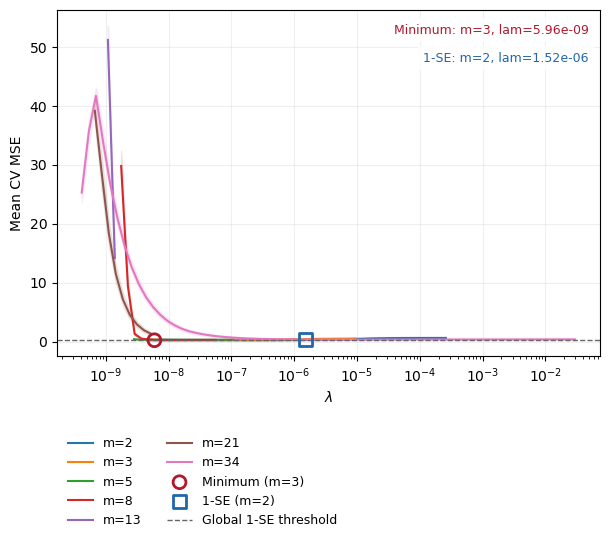

Fresh CV one-SE: 2 1.5213449981401241e-06
Paper-tuned nonzeros: 8 KKT residual: 0.1142966083707884


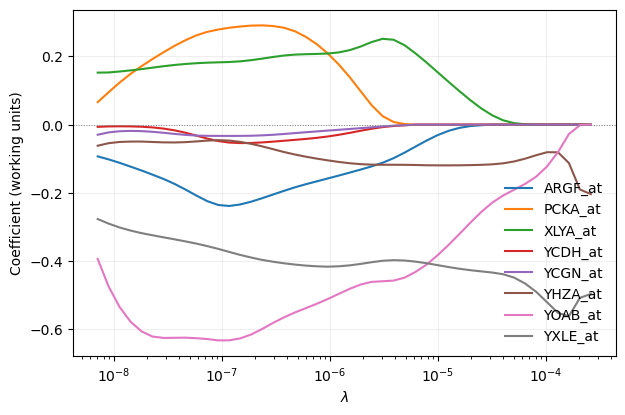

In [ ]:
LAMBDA_GRIDS = {2: [7.04225352112676e-09, 8.89636010091574e-09, 1.1238621672413504e-08, 1.419756121187599e-08, 1.7935539627581237e-08, 2.2657664716631377e-08, 2.8623045699825135e-08, 3.6159010885747e-08, 4.567906860602034e-08, 5.770559696189008e-08, 7.289850739840226e-08, 9.209145491423487e-08, 1.1633758180906775e-07, 1.46967304988136e-07, 1.8566131768945064e-07, 2.3454281133457358e-07, 2.9629397783731826e-07, 3.743031850054414e-07, 4.7285090074339e-07, 5.973445679618888e-07, 7.546153180899172e-07, 9.532928042500852e-07, 1.2042787216873186e-06, 1.5213449981401241e-06, 1.9218894776477778e-06, 2.427890563158798e-06, 3.067113200437561e-06, 3.874632377193787e-06, 4.894757733838004e-06, 6.1834648917890594e-06, 7.811466909519015e-06, 9.868094401172534e-06, 1.246619722497791e-05, 1.5748336703546482e-05, 1.989460815134093e-05, 2.513252294169384e-05, 3.1749492355404545e-05, 4.010859821612294e-05, 5.0668515668047844e-05, 6.400868128498198e-05, 8.086108751802429e-05, 0.00010215044808510503, 0.00012904493823016902, 0.0001630202940368337, 0.00020594078801025522, 0.00026016152416399304], 3: [4.6948356807511736e-09, 5.955003309935663e-09, 7.55341972174642e-09, 9.580876201642983e-09, 1.2152533841980839e-08, 1.5414464780910525e-08, 1.955194921252749e-08, 2.4799999444850878e-08, 3.145670878024429e-08, 3.990018344498587e-08, 5.0610019314651303e-08, 6.41945433298818e-08, 8.14253669359712e-08, 1.0328121420830052e-07, 1.3100351413496063e-07, 1.6616691474110842e-07, 2.1076872431172584e-07, 2.673423600432431e-07, 3.3910124809497075e-07, 4.301213486742883e-07, 5.455726737212575e-07, 6.920129475757747e-07, 8.777600907797316e-07, 1.1133646843815413e-06, 1.412209251080059e-06, 1.791268392839249e-06, 2.272072961376604e-06, 2.881933027152969e-06, 3.6554891124459826e-06, 4.636679799742566e-06, 5.8812374771252855e-06, 7.459853980916134e-06, 9.462195946522361e-06], 5: [2.8169014084507043e-09, 3.5913004925831367e-09, 4.578590925949896e-09, 5.837299025933692e-09, 7.442040677852708e-09, 9.487944545029639e-09, 1.2096291270949081e-08, 1.5421702963924955e-08, 1.966130915503915e-08, 2.5066432584929103e-08, 3.1957487549793045e-08, 4.074297397664837e-08, 5.194369319163191e-08, 6.622362088572172e-08, 8.44292674191736e-08, 1.0763985873317358e-07], 8: [1.76056338028169e-09, 2.255137164987323e-09, 2.8886455834912156e-09, 3.7001178627066766e-09, 4.739547238389227e-09, 6.0709709415825986e-09, 7.776415408419145e-09, 9.960949770010656e-09, 1.2759158958156238e-08, 1.634343522237486e-08, 2.0934598882570945e-08, 2.681550264133868e-08, 3.4348457591241664e-08, 4.3997554499632004e-08, 5.6357255542143595e-08], 13: [1.0834236186348862e-09, 1.3945308640302949e-09], 21: [6.70690811535882e-10, 8.674310176057135e-10, 1.1218829263239877e-09, 1.4509756681877974e-09, 1.876604358862512e-09, 2.427086819519282e-09, 3.139047611002482e-09, 4.059854729915279e-09, 5.250771084275366e-09], 34: [4.1425020712510353e-10, 5.383539718336732e-10, 6.996375475596669e-10, 9.092395033105394e-10, 1.1816353728641093e-09, 1.535637364324704e-09, 1.995693569154281e-09, 2.593576396674345e-09, 3.3705768407305317e-09, 4.380356119000994e-09, 5.692651624910241e-09, 7.3980931326615096e-09, 9.614461872220505e-09, 1.2494824738591325e-08, 1.623810540028248e-08, 2.1102822369032287e-08, 2.742494280959541e-08, 3.564108510970095e-08, 4.631867262645648e-08, 6.019512108773892e-08, 7.82287660095399e-08, 1.0166504727941923e-07, 1.3212252174687396e-07, 1.7170464402358068e-07, 2.2314503530100983e-07, 2.8999627274292244e-07, 3.7687523762894685e-07, 4.897819664868135e-07, 6.365140257155091e-07, 8.272050272464896e-07, 1.0750244762205762e-06, 1.3970872835725151e-06, 1.815635756296527e-06, 2.3595756960244066e-06, 3.0664726919818246e-06, 3.98514647634046e-06, 5.1790425133787265e-06, 6.730613671198151e-06, 8.747014583080858e-06, 1.1367501962567583e-05, 1.4773051952940089e-05, 1.9198858704658793e-05, 2.49505773577203e-05, 3.2425433202053916e-05, 4.21396548571462e-05, 5.4764126061604155e-05, 7.11707182571447e-05, 9.249250378870209e-05, 0.00012020200816568608, 0.00015621290564337112, 0.00020301218142635747, 0.00026383188788241577, 0.00034287235659723013, 0.00044559228174470236, 0.0005790857085153961, 0.0007525719621842722, 0.0009780323533072097, 0.0012710376311912365, 0.0016518233312439044, 0.002146687281858443, 0.0027898057854786064, 0.00362559390297033, 0.004711772847298944, 0.006123356326905563, 0.007957831143695505, 0.010341889828183893, 0.013440180281159524, 0.01746667668976615, 0.022699457016398018, 0.02949990762359492]}

cv_by_m = {}
for m, grid in sorted(LAMBDA_GRIDS.items()):
    cv_by_m[m] = cv_fridge(X, y, ms=[m], lambdas=grid, n_folds=N_FOLDS,
                           random_state=RANDOM_STATE, method="smooth", selection="1se",
                           ridge_init=1e-6/(n*m), **PATH_OPTIONS)
    print(f"CV complete for m={m}")

records = {m: fit.results_[m] for m, fit in cv_by_m.items()}
best_error, best_m, best_index = min((float(r["mean_mse"][i]), m, i)
    for m, r in records.items() for i in range(len(r["lambdas"])))

one_se_threshold = best_error + records[best_m]["se_mse"][best_index]
one_m = next(m for m in sorted(records) if np.any(records[m]["mean_mse"] <= one_se_threshold))
valid = np.flatnonzero(records[one_m]["mean_mse"] <= one_se_threshold)
one_index = int(valid[np.argmax(records[one_m]["lambdas"][valid])])
one_lam = float(records[one_m]["lambdas"][one_index])

selected_path = cv_by_m[one_m].path_
selected_fit = replace(cv_by_m[one_m].fit_, lam=one_lam,
    coef_=selected_path.coef_path_[one_index].copy(),
    scaled_coef_=selected_path.scaled_coef_path_[one_index].copy(),
    intercept_=float(selected_path.intercepts_[one_index]),
    n_iter_=int(selected_path.n_iter_[one_index]),
    converged_=bool(selected_path.converged_[one_index]),
    kkt_residual_=float(selected_path.kkt_residuals_[one_index]),
    objective_history_=np.array([selected_path.objectives_[one_index]]))

fresh_cv = FridgeCV(records, best_m, float(records[best_m]["lambdas"][best_index]),
                    one_m, one_lam, float(one_se_threshold), "1se", selected_fit,
                    method="smooth", path_=selected_path)
plot_cv_fridge(fresh_cv); plt.show()

PAPER_M = 2
PAPER_LAM = 0.00017238022998427468 / n
paper_path = path_fridge(X, y, m=PAPER_M, lambdas=LAMBDA_GRIDS[PAPER_M],
                         ridge_init=1e-6/(n*PAPER_M), **PATH_OPTIONS)
paper_index = int(np.argmin(abs(paper_path.lambdas_-PAPER_LAM)))

assert np.isclose(paper_path.lambdas_[paper_index], PAPER_LAM, rtol=1e-12, atol=0)

fridge_beta = paper_path.coef_path_[paper_index].copy()

print("Fresh CV one-SE:", one_m, one_lam)
print("Paper-tuned nonzeros:", np.count_nonzero(fridge_beta),
      "KKT residual:", paper_path.kkt_residuals_[paper_index])
plot_path_fridge(paper_path, feature_names=genes,
                 features=np.flatnonzero(fridge_beta != 0), legend=True)
plt.show()

## Comparison methods

Adaptive Lasso uses a cross-validated ridge pilot and cross-validated weighted L1 fit. SCAD uses R `ncvreg` with ten folds and seed 0. SuSiE is fitted with at most 34 effects.

In [ ]:
pilot = RidgeCV(cv=5).fit(X, y)
weights = 1/(np.abs(pilot.coef_)+1e-8)

adaptive = LassoCV(cv=N_FOLDS, random_state=42).fit(X/weights, y)
adalasso_beta = adaptive.coef_/weights

susie_fit = pysusie.susie(X, y, L=34)
pip = np.asarray(susie_fit.pip)
raw_sets = susie_fit.sets.get("cs", [])
if isinstance(raw_sets, dict):
    raw_sets = list(raw_sets.values())

credible_sets = [np.asarray(indices, dtype=int) for indices in raw_sets]
assert pip.shape == (p,) and np.all((pip >= 0) & (pip <= 1))

with TemporaryDirectory() as temporary:
    folder = Path(temporary)
    pd.DataFrame(X, columns=genes).to_csv(folder/"X.csv", index=False)
    pd.DataFrame({"y": y}).to_csv(folder/"y.csv", index=False)
    
    r_code = r"""
    args <- commandArgs(trailingOnly=TRUE); folder <- args[1]
    if (!requireNamespace("ncvreg", quietly=TRUE)) stop("Install R package ncvreg.")
    X <- as.matrix(read.csv(file.path(folder,"X.csv"),check.names=FALSE))
    y <- read.csv(file.path(folder,"y.csv"))$y
    set.seed(0)
    fit <- ncvreg::cv.ncvreg(X,y,family="gaussian",penalty="SCAD",nfolds=10)
    write.csv(data.frame(gene=colnames(X),beta=as.numeric(coef(fit))[-1]),
              file.path(folder,"scad.csv"),row.names=FALSE)
    """
    subprocess.run([R_SCRIPT,"--vanilla","-e",r_code,str(folder)],check=True)
    scad = pd.read_csv(folder/"scad.csv").set_index("gene").loc[genes]

scad_beta = scad.beta.to_numpy()

During startup - Warning message:
Setting LC_CTYPE failed, using "C" 


## SuSiE concordance and expression groups

Count the full nonzero set, overlap with the ten highest PIPs, overlap among the three leading coefficients, and credible-set membership. Group A is the empirical correlation group from the paper; group B is the reported five-gene SuSiE group. Recomputed credible sets are shown independently.

,nonzero,in_top10,leading3_in_top10,in_credible_set,correlated_pairs
method,,,,,
Fridge,8,3,3,1,0
SCAD,16,3,2,1,0
Adaptive Lasso,53,5,1,3,4


Recomputed CS1: ['YXLC_at', 'YXLD_at', 'YXLE_at', 'YXLF_at', 'YXLG_at']
Group A Fridge representatives: ['XLYA_at']
Group B Fridge representatives: ['YXLE_at']


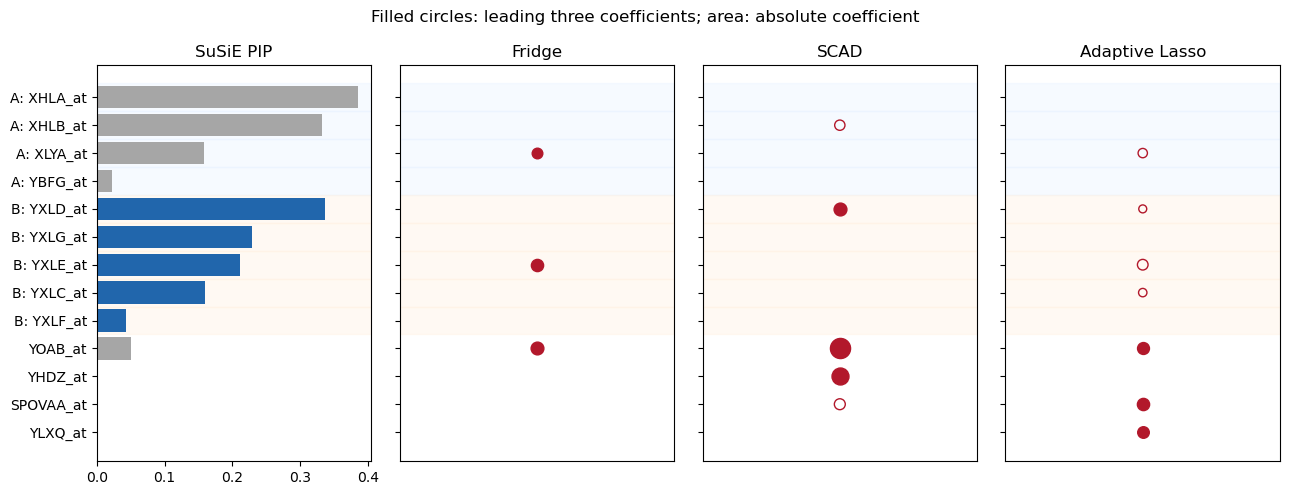

In [ ]:
methods = {"Fridge": fridge_beta, "SCAD": scad_beta, "Adaptive Lasso": adalasso_beta}

top_pip = set(np.argsort(-pip, kind="stable")[:10])
cs_union = set(np.concatenate(credible_sets).tolist()) if credible_sets else set()

rows = []
for name, beta in methods.items():
    nonzero = np.flatnonzero(beta != 0)
    leading = np.argsort(-np.abs(beta), kind="stable")[:min(3,len(nonzero))]
    corr = np.corrcoef(X[:,nonzero], rowvar=False) if len(nonzero)>1 else np.zeros((1,1))
    rows.append(dict(method=name, nonzero=len(nonzero), in_top10=len(set(nonzero)&top_pip),
                     leading3_in_top10=len(set(leading)&top_pip),
                     in_credible_set=len(set(nonzero)&cs_union),
                     correlated_pairs=int(np.sum(np.triu(np.abs(corr)>0.9,1)))))

summary = pd.DataFrame(rows).set_index("method")
display(summary)

for i, members in enumerate(credible_sets, 1):
    print(f"Recomputed CS{i}:", list(genes[members]))

group_A = ["XHLA_at","XHLB_at","XLYA_at","YBFG_at"]
group_B = ["YXLC_at","YXLD_at","YXLE_at","YXLF_at","YXLG_at"]
for name, group in [("A",group_A),("B",group_B)]:
    indices = np.array([np.flatnonzero(genes==g)[0] for g in group])
    print(f"Group {name} Fridge representatives:", list(genes[indices[fridge_beta[indices]!=0]]))

shown = top_pip | cs_union
for beta in methods.values():
    shown |= set(np.argsort(-np.abs(beta),kind="stable")[:3])

shown = sorted(shown,key=lambda j: (0 if genes[j] in group_A else 1 if genes[j] in group_B else 2,-pip[j]))

fig, axes = plt.subplots(1,4,figsize=(13,max(5,len(shown)*.3)),sharey=True)
positions = np.arange(len(shown))
labels = [("A: " if genes[j] in group_A else "B: " if genes[j] in group_B else "")+genes[j] for j in shown]
axes[0].barh(positions,pip[shown],color=["#2166ac" if j in cs_union else "0.65" for j in shown])
axes[0].set_yticks(positions,labels); axes[0].invert_yaxis();axes[0].set_title("SuSiE PIP")
maximum = max(np.max(np.abs(beta[shown])) for beta in methods.values())

for ax,(name,beta) in zip(axes[1:],methods.items()):
    leading=set(np.argsort(-np.abs(beta),kind="stable")[:3])
    for row,j in enumerate(shown):
        if beta[j]!=0:
            ax.scatter(0,row,s=30+180*abs(beta[j])/maximum,
                       facecolors="#b2182b" if j in leading else "none",edgecolors="#b2182b")
    ax.set_title(name);ax.set_xticks([]);ax.set_xlim(-1,1)

for ax in axes:
    for row,j in enumerate(shown):
        if genes[j] in group_A:ax.axhspan(row-.5,row+.5,color="#e6f2ff",alpha=.35,zorder=-1)
        elif genes[j] in group_B:ax.axhspan(row-.5,row+.5,color="#fff0df",alpha=.35,zorder=-1)

fig.suptitle("Filled circles: leading three coefficients; area: absolute coefficient")
fig.tight_layout();plt.show()

## Fixed-tuning bootstrap

Use 500 resamples to distinguish gene selection from selecting any member of group B. Adaptive weights are re-estimated in every resample; CV is not repeated. Fresh resampling need not reproduce historical percentages exactly.

In [ ]:
if RUN_BOOTSTRAP:
    rng = np.random.default_rng(RANDOM_STATE)
    bootstrap = np.empty((N_BOOTSTRAP,p))
    for draw in range(N_BOOTSTRAP):
        rows = rng.integers(0,n,size=n)
        fitted = path_fridge(X[rows],y[rows],m=PAPER_M,lambdas=LAMBDA_GRIDS[PAPER_M],
                            ridge_init=1e-6/(n*PAPER_M),**PATH_OPTIONS)
        bootstrap[draw] = fitted.coef_path_[paper_index]
        
        if (draw+1)%25==0:
            print(f"Bootstrap {draw+1}/{N_BOOTSTRAP}")
    
    indices = np.array([np.flatnonzero(genes==g)[0] for g in group_B])
    print("Selection of any group-B member:",np.mean(np.any(bootstrap[:,indices]!=0,axis=1)))
    print("YXLE_at selection:",np.mean(bootstrap[:,np.flatnonzero(genes=='YXLE_at')[0]]!=0))
    display(pd.DataFrame(dict(gene=genes,beta=fridge_beta,bootstrap_sd=bootstrap.std(axis=0),
                             selection_frequency=np.mean(bootstrap!=0,axis=0))).loc[fridge_beta!=0])

Bootstrap 25/500


Bootstrap 50/500


Bootstrap 75/500


Bootstrap 100/500


Bootstrap 125/500


...

Bootstrap 425/500


Bootstrap 450/500


Bootstrap 475/500


Bootstrap 500/500
Selection of any group-B member: 0.968
YXLE_at selection: 0.562


,gene,beta,bootstrap_sd,selection_frequency
72,ARGF_at,-0.122258,0.089182,0.550
791,PCKA_at,0.056843,0.096822,0.206
1302,XLYA_at,0.242010,0.114120,0.576
1477,YCDH_at,-0.011965,0.081103,0.438
1501,YCGN_at,-0.007732,0.094139,0.342
2094,YHZA_at,-0.117133,0.086826,0.668
2563,YOAB_at,-0.460600,0.141623,0.060
4003,YXLE_at,-0.402968,0.205031,0.562


In [ ]:
import importlib.metadata

versions = {}
for package in ["pyfridge","numpy","scipy","pandas","scikit-learn","matplotlib","pysusie"]:
    try:
        versions[package]=importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        versions[package]="source checkout"

print(json.dumps(
    dict(data_url=DATA_URL,data_sha256=data_sha256,versions=versions,
                     paper_m=PAPER_M,paper_normalized_lam=PAPER_LAM,
                     fresh_one_se_m=one_m,fresh_one_se_lam=one_lam,
                     bootstrap_draws=N_BOOTSTRAP if RUN_BOOTSTRAP else 0),
    indent=2
))


{
  "data_url": "https://raw.githubusercontent.com/cran/hdi/master/data/riboflavin.RData",
  "data_sha256": "ff5c2257a46367992cfb329041ffb5fef77663761811fef8c55043c274d8d2c5",
  "versions": {
    "pyfridge": "0.1.0",
    "numpy": "2.2.6",
    "scipy": "1.16.1",
    "pandas": "2.3.2",
    "scikit-learn": "1.7.1",
    "matplotlib": "3.10.6",
    "pysusie": "0.1.0"
  },
  "paper_m": 2,
  "paper_normalized_lam": 2.427890563158798e-06,
  "fresh_one_se_m": 2,
  "fresh_one_se_lam": 1.5213449981401241e-06,
  "bootstrap_draws": 500
}


## References

- Park, S. and Stefanski, L. A. *Fractional Ridge Regression*. [arXiv:2505.23925v3](https://arxiv.org/html/2505.23925v3).
- Dataset: [CRAN hdi documentation](https://rdrr.io/cran/hdi/man/riboflavin.html), attributed to Bühlmann, Kalisch, and Meier (2014).
- Wang et al. (2020), *A simple new approach to variable selection in regression, with application to genetic fine mapping* (SuSiE).